# Transfer Learning & data-augmentation bij CNN's

Wanneer je een neuraal netwerk traint op een beperkt aantal beelden, loop je al snel tegen het probleem aan van *overfitting* en onvoldoende generalisatie. Gelukkig biedt *transfer learning* een krachtige oplossing, vooral binnen computer vision-toepassingen.

Om dit te illustreren, bouwen we hieronder een model wat foto's van katten en honden kan onderscheiden.  Het model kan dus voorspellen of een kat of een hond aanwezig is op een afbeelding.  

We bouwen telkens op een andere manier dit model:
- basic, from scratch
- met data augmentation
- met feature extraction via een pretrained model
- finetunen van een pretrained model

In [ ]:
# Import Keras libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation
from tensorflow.keras.optimizers import SGD
from tensorflow.keras.layers import Dense, Dropout,BatchNormalization
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras import backend as K
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing import image
from tensorflow.keras import layers

# Libraries voor Early stopping, ModelCheckpoint en load_model
from tensorflow.keras.models import load_model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint

## 1. Bouwen van een model 'from scratch'

### 1.1 Inlezen en valideren van de data (afbeeldingen van honden en katten)
#### 1.1.1 Checken of er geen foute, lege of corrupte afbeeldingen aanwezig zijn

In [52]:
# Via python - maar nog steeds errors aanwezig!
from pathlib import Path
from PIL import Image

def clean_invalid_images(directory):
    for file_path in Path(directory).rglob("*.jpg"):
        try:
            # Probeer afbeelding te openen en te verifiëren (corrupt of leeg?)
            img = Image.open(file_path)
            img.verify()  # let op: dit sluit het bestand af

            # Heropen om mode te kunnen controleren
            # Modellen zoals VGG16 vereisen RGB-input van exact 3 kanalen!
            img = Image.open(file_path)
            if img.mode not in ["L", "RGB", "RGBA"]:
                print(f"Verwijderen (verkeerde mode): {file_path} (mode: {img.mode})")
                file_path.unlink()
        except Exception as e:
            print(f"Verwijderen (corrupt of leeg): {file_path} ({e})")
            file_path.unlink()

# Voer dit uit op je datasetmap
clean_invalid_images("CatsVsDogs/PetImages")
# Controleer je mappen
broken_files = check_images("CatsVsDogs/PetImages")
print(f"Aantal corrupte of lege bestanden: {len(broken_files)}")
print("Voorbeelden:", broken_files[:5])

Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/850.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/4833.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/9171.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/9565.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/7968.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/11565.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/3300.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/5370.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/11095.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/2663.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/660.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/10820.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDogs/PetImages/Cat/140.jpg (mode: P)
Verwijderen (verkeerde mode): CatsVsDo

In [59]:
# Extra check via tensorflow
import tensorflow as tf
from pathlib import Path

def remove_unreadable_images_tf(directory):
    count_removed = 0
    for file_path in Path(directory).rglob("*.jpg"):
        try:
            img = tf.io.read_file(str(file_path))
            img = tf.image.decode_jpeg(img)  # als dit mislukt → exception
        except Exception as e:
            print(f"Verwijderen (TensorFlow decode error): {file_path} – {e}")
            file_path.unlink()
            count_removed += 1
    print(f"Totaal verwijderd met TensorFlow controle: {count_removed}")

# Pas toe op je dataset
remove_unreadable_images_tf("CatsVsDogs/PetImages")

Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/6029.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/391.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/9361.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/4821.jpg – {{function_node __wrapped__DecodeJpeg_device_/j

Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/1151.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/9208.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/5819.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/5077.jpg – {{function_node __wrapped__DecodeJpeg_device_/

Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/2569.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/11729.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/7502.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Cat/4929.jpg – {{function_node __wrapped__DecodeJpeg_device_

Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/9556.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/3038.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/4654.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/565.jpg – {{function_node __wrapped__DecodeJpeg_device_/j

Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/9640.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/4257.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/522.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/12114.jpg – {{function_node __wrapped__DecodeJpeg_device_/

Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/1017.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/9367.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/10907.jpg – {{function_node __wrapped__DecodeJpeg_device_/job:localhost/replica:0/task:0/device:CPU:0}} Trying to decode BMP format using a wrong op. Use `decode_bmp` or `decode_image` instead. Op used: DecodeJpeg [Op:DecodeJpeg]
Verwijderen (TensorFlow decode error): CatsVsDogs/PetImages/Dog/11590.jpg – {{function_node __wrapped__DecodeJpeg_device

In [60]:
# Maken van de dataset - opdelen vanaf de volledige dataset naar train/validation/test dataset

import os, shutil, pathlib

# Pad naar de originele dataset (waar alle 'cat.0.jpg', 'dog.0.jpg' enz. zich bevinden)
original_dir = pathlib.Path("CatsVsDogs/PetImages")

# Nieuwe basisdirectory waarin we de kleinere dataset zullen opslaan
new_base_dir = pathlib.Path("cats_vs_dogs_small")

# Functie om subsets te maken
def make_subset(subset_name, start_index, end_index):
    for category in ("Cat", "Dog"):
        # Pad naar de doelmap: bv. cats_vs_dogs_small/train/cat/
        dir = new_base_dir / subset_name / category
        os.makedirs(dir)
        fnames = [f"{i}.jpg" for i in range(start_index, end_index)]
        for fname in fnames:
            try:
                shutil.copyfile(src=original_dir / category / fname, dst=dir / fname)
            except FileNotFoundError as e:
                print(f"not found: {fname} - ", end=" ")
# Maak de trainingsset: 0–1999 = 2000 beelden per categorie
make_subset("train", start_index=0, end_index=2000)

# Maak de validatieset: 2000–2499 = 500 beelden per categorie
make_subset("validation", start_index=2000, end_index=2500)

# Maak de testset: 2500–3499 = 1000 beelden per categorie
make_subset("test", start_index=2500, end_index=3500)

not found: 23.jpg -  not found: 140.jpg -  not found: 391.jpg -  not found: 445.jpg -  not found: 660.jpg -  not found: 666.jpg -  not found: 850.jpg -  not found: 910.jpg -  not found: 936.jpg -  not found: 1151.jpg -  not found: 1267.jpg -  not found: 1386.jpg -  not found: 1757.jpg -  not found: 1914.jpg -  not found: 1936.jpg -  not found: 1937.jpg -  not found: 50.jpg -  not found: 296.jpg -  not found: 414.jpg -  not found: 522.jpg -  not found: 543.jpg -  not found: 561.jpg -  not found: 565.jpg -  not found: 573.jpg -  not found: 663.jpg -  not found: 719.jpg -  not found: 1017.jpg -  not found: 1168.jpg -  not found: 1259.jpg -  not found: 1308.jpg -  not found: 1356.jpg -  not found: 1789.jpg -  not found: 1866.jpg -  not found: 1884.jpg -  not found: 1900.jpg -  not found: 2021.jpg -  not found: 2189.jpg -  not found: 2317.jpg -  not found: 2353.jpg -  not found: 2384.jpg -  not found: 2479.jpg -  not found: 2494.jpg -  not found: 2569.jpg -  not found: 2663.jpg -  not found

In [61]:
# laden van de dataset vanaf de hierboven gemaakte folders

from tensorflow.keras.utils import image_dataset_from_directory

train_dataset = image_dataset_from_directory(
    new_base_dir / "train",
    image_size=(180, 180),
    batch_size=32
)

validation_dataset = image_dataset_from_directory(
    new_base_dir / "validation",
    image_size=(180, 180),
    batch_size=32
)

test_dataset = image_dataset_from_directory(
    new_base_dir / "test",
    image_size=(180, 180),
    batch_size=32
)

Found 3965 files belonging to 2 classes.
Found 993 files belonging to 2 classes.
Found 1983 files belonging to 2 classes.


In [63]:
# Het model

inputs = keras.Input(shape=(180, 180, 3))
x = layers.Rescaling(1./255)(inputs)  # Schaal inputwaarden naar [0, 1]

x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.Flatten()(x)

outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs=inputs, outputs=outputs)

In [64]:
# Callbacks

callbacks = [keras.callbacks.ModelCheckpoint(
    filepath="convnet_from_scratch.keras", 
    save_best_only=True, 
    monitor="val_loss")
]

In [65]:
# Compileren van het model

model.compile(loss="binary_crossentropy", 
              optimizer="rmsprop", 
              metrics=["accuracy"])

In [66]:
history = model.fit(train_dataset, 
                    epochs=30, 
                    validation_data=validation_dataset, 
                    callbacks=callbacks)

Epoch 1/30
124/124 [==============================] - 50s 397ms/step - loss: 0.7071 - accuracy: 0.4976 - val_loss: 0.6909 - val_accuracy: 0.5015
Epoch 2/30
124/124 [==============================] - 49s 393ms/step - loss: 0.6920 - accuracy: 0.5602 - val_loss: 0.7047 - val_accuracy: 0.5398
Epoch 3/30
124/124 [==============================] - 49s 393ms/step - loss: 0.6528 - accuracy: 0.6232 - val_loss: 0.6262 - val_accuracy: 0.6576
Epoch 4/30
124/124 [==============================] - 49s 393ms/step - loss: 0.6104 - accuracy: 0.6736 - val_loss: 0.5779 - val_accuracy: 0.7069
Epoch 5/30
124/124 [==============================] - 49s 392ms/step - loss: 0.5728 - accuracy: 0.7203 - val_loss: 0.5393 - val_accuracy: 0.7321
Epoch 6/30
124/124 [==============================] - 49s 394ms/step - loss: 0.5233 - accuracy: 0.7380 - val_loss: 0.5209 - val_accuracy: 0.7472
Epoch 7/30
124/124 [==============================] - 49s 393ms/step - loss: 0.4810 - accuracy: 0.7745 - val_loss: 0.4983 - val_ac

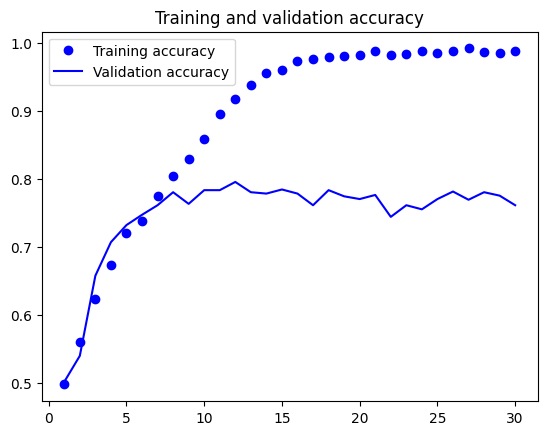

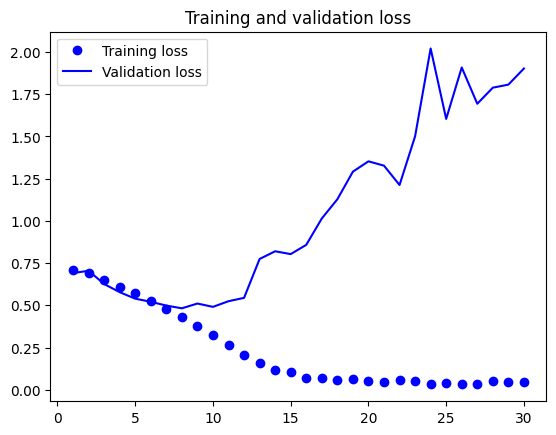

In [67]:
import matplotlib.pyplot as plt

accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(accuracy) + 1)

# Plot accuracy
plt.plot(epochs, accuracy, "bo", label="Training accuracy")
plt.plot(epochs, val_accuracy, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.legend()

# Plot loss
plt.figure()
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.legend()

plt.show()

Deze grafieken zijn kenmerkend voor overfitting. De training accuracy stijgt lineair in de tijd tot ze bijna 100% bereikt, terwijl de validatie accuracy blijft hangen rond de 75%.
Het validation loss bereikt zijn minimum al na tien epochs en blijft daarna stabiel, terwijl het training loss blijft dalen naarmate de training vordert.

Laten we nu de accuracy op de testset bekijken. We laden het model opnieuw in vanuit het opgeslagen bestand, zodat we het kunnen evalueren zoals het was vóór het begon te overfitten.

In [68]:
test_model = keras.models.load_model("convnet_from_scratch.keras")

In [69]:
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")

62/62 [==============================] - 5s 73ms/step - loss: 0.4858 - accuracy: 0.7736
Test accuracy: 0.774


We behalen een testnauwkeurigheid van ongeveer 77%. (Door de willekeur bij het initialiseren van neurale netwerken kan dit cijfer licht variëren, meestal binnen één procentpunt.)

Omdat we relatief weinig trainingsvoorbeelden hebben (4.000), is overfitting onze grootste bezorgdheid. Je kent al enkele technieken die kunnen helpen om overfitting te beperken, zoals dropout en weight decay (L2-regularisatie).

We gaan nu aan de slag met een nieuwe techniek, specifiek voor computer vision en vrijwel standaard bij het verwerken van beelden met deep learning modellen: data-augmentatie.

### Overfitting en data-augmentatie

**Overfitting** ontstaat wanneer je te weinig trainingsdata hebt, waardoor het model niet goed leert generaliseren naar nieuwe, ongeziene data.  
In een ideale wereld met **oneindig veel gegevens** zou het model alle mogelijke variaties leren kennen — en zou overfitting geen probleem zijn.

**Data-augmentatie** is een oplossing die hierop inspeelt:  
Je maakt **meer trainingsvoorbeelden** door de bestaande afbeeldingen **willekeurig te transformeren** (zoals draaien, spiegelen, inzoomen, enz.). Deze bewerkingen zorgen voor **realistisch ogende variaties**, zodat het model telkens iets nieuws te zien krijgt.

Het doel is dat het model **tijdens de training nooit twee keer exact dezelfde afbeelding** ziet, waardoor het beter leert generaliseren.

In **Keras** kun je dit eenvoudig toepassen door **data-augmentatielagen** toe te voegen aan het begin van je model. Dit gebeurt typisch **vóór de Rescaling-laag**.

In [70]:
data_augmentation = keras.Sequential(
    [ 
        layers.RandomFlip("horizontal"), 
        layers.RandomRotation(0.1), 
        layers.RandomZoom(0.2), 
    ] 
)

De onderstaande lagen zijn enkele van de beschikbare augmentatielagen in Keras (voor een volledig overzicht kun je de Keras-documentatie raadplegen):

- **`RandomFlip("horizontal")`**  
  Spiegelt de helft van de afbeeldingen willekeurig horizontaal.

- **`RandomRotation(0.1)`**  
  Draait elke afbeelding met een willekeurige hoek tussen **–10% en +10%** van een volledige rotatie (*gelijk aan –36° tot +36°*).

- **`RandomZoom(0.2)`**  
  Zoomt willekeurig **in of uit met maximaal 20%**.

Deze lagen zorgen voor realistische variatie in de input tijdens training, waardoor het model robuuster leert.

In [71]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

# Neem slechts één batch uit de trainingsdataset
for images, _ in train_dataset.take(1):

    # Voer 9 keer augmentatie uit op dezelfde batch
    for i in range(9):
        # Pas de augmentatielagen toe (bijv. RandomFlip, RandomZoom, etc.)
        augmented_images = data_augmentation(images)

        # Teken de subplot (3 rijen × 3 kolommen)
        ax = plt.subplot(3, 3, i + 1)

        # Toon de eerste afbeelding in de batch, geconverteerd naar een toonbare vorm
        plt.imshow(augmented_images[0].numpy().astype("uint8"))
        plt.axis("off")

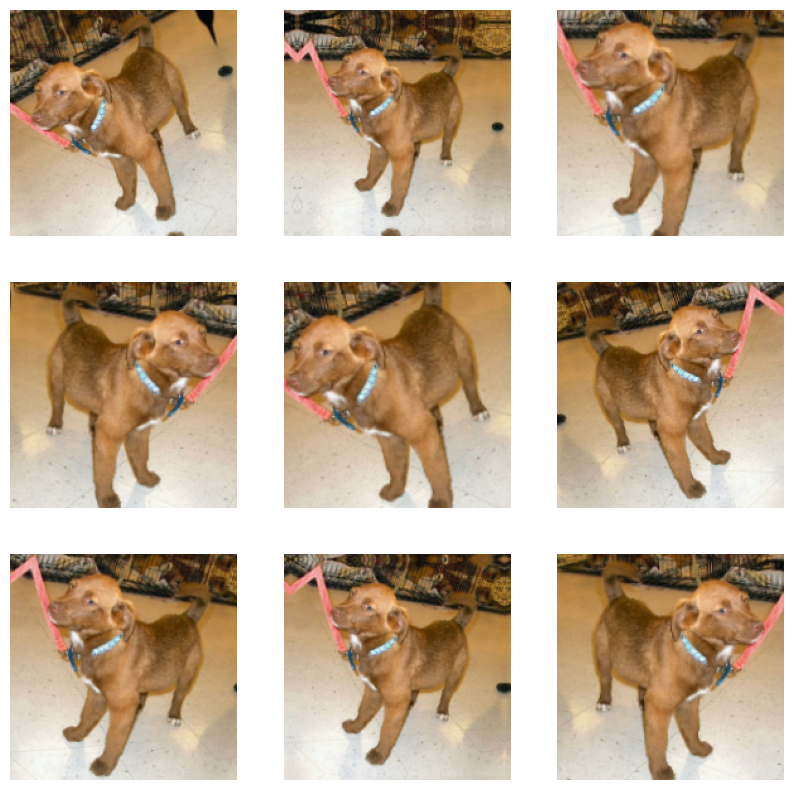

In [72]:
plt.show()

Om overfitting verder tegen te gaan, voegen we een **Dropout-laag** toe aan ons model, net vóór de dense classifier.

Nog een laatste belangrijk punt over de willekeurige data-augmentatielagen:  
Net als bij Dropout zijn deze **niet actief tijdens de inferentie** (bijvoorbeeld wanneer je `predict()` of `evaluate()` aanroept).  

Tijdens het evalueren van het model gedraagt het zich dus **precies zoals wanneer er géén data-augmentatie of dropout zou zijn toegepast**.

In [73]:
inputs = keras.Input(shape=(180, 180, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1./255)(x)

x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)

x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
x = layers.Dropout(0.5)(x)

x = layers.Flatten()(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.compile(
    loss="binary_crossentropy",
    optimizer="rmsprop",
    metrics=["accuracy"]
)

In [74]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="convnet_from_scratch_with_augmentation.keras",
        save_best_only=True,
        monitor="val_loss"
    )
]

history = model.fit(
    train_dataset,
    epochs=100,
    validation_data=validation_dataset,
    callbacks=callbacks
)

Epoch 1/100
124/124 [==============================] - 54s 422ms/step - loss: 0.7023 - accuracy: 0.5180 - val_loss: 0.6732 - val_accuracy: 0.6012
Epoch 2/100
124/124 [==============================] - 52s 422ms/step - loss: 0.6809 - accuracy: 0.5760 - val_loss: 0.6309 - val_accuracy: 0.6334
Epoch 3/100
124/124 [==============================] - 53s 426ms/step - loss: 0.6471 - accuracy: 0.6240 - val_loss: 0.6118 - val_accuracy: 0.6636
Epoch 4/100
124/124 [==============================] - 53s 426ms/step - loss: 0.6197 - accuracy: 0.6502 - val_loss: 0.5784 - val_accuracy: 0.6928
Epoch 5/100
124/124 [==============================] - 53s 427ms/step - loss: 0.6129 - accuracy: 0.6691 - val_loss: 0.5955 - val_accuracy: 0.6848
Epoch 6/100
124/124 [==============================] - 52s 423ms/step - loss: 0.5921 - accuracy: 0.6863 - val_loss: 0.5525 - val_accuracy: 0.7049
Epoch 7/100
124/124 [==============================] - 53s 424ms/step - loss: 0.5737 - accuracy: 0.7039 - val_loss: 0.5536 -

124/124 [==============================] - 53s 429ms/step - loss: 0.2109 - accuracy: 0.9170 - val_loss: 0.4510 - val_accuracy: 0.8560
Epoch 41/100
124/124 [==============================] - 53s 430ms/step - loss: 0.2091 - accuracy: 0.9198 - val_loss: 0.4740 - val_accuracy: 0.8610
Epoch 42/100
124/124 [==============================] - 53s 425ms/step - loss: 0.2079 - accuracy: 0.9185 - val_loss: 0.4659 - val_accuracy: 0.8479
Epoch 43/100
124/124 [==============================] - 53s 428ms/step - loss: 0.1897 - accuracy: 0.9284 - val_loss: 0.7558 - val_accuracy: 0.8238
Epoch 44/100
124/124 [==============================] - 53s 428ms/step - loss: 0.1962 - accuracy: 0.9213 - val_loss: 0.4194 - val_accuracy: 0.8550
Epoch 45/100
124/124 [==============================] - 53s 427ms/step - loss: 0.1865 - accuracy: 0.9284 - val_loss: 0.4011 - val_accuracy: 0.8721
Epoch 46/100
124/124 [==============================] - 53s 426ms/step - loss: 0.1835 - accuracy: 0.9261 - val_loss: 0.4610 - val_a

Epoch 96/100
124/124 [==============================] - 55s 444ms/step - loss: 0.1717 - accuracy: 0.9531 - val_loss: 0.5349 - val_accuracy: 0.8812
Epoch 97/100
124/124 [==============================] - 54s 433ms/step - loss: 0.1509 - accuracy: 0.9556 - val_loss: 0.7453 - val_accuracy: 0.8862
Epoch 98/100
124/124 [==============================] - 57s 462ms/step - loss: 0.1740 - accuracy: 0.9521 - val_loss: 0.6046 - val_accuracy: 0.8872
Epoch 99/100
124/124 [==============================] - 55s 442ms/step - loss: 0.1754 - accuracy: 0.9491 - val_loss: 0.8120 - val_accuracy: 0.8640
Epoch 100/100
124/124 [==============================] - 53s 428ms/step - loss: 0.1646 - accuracy: 0.9516 - val_loss: 0.7101 - val_accuracy: 0.8741


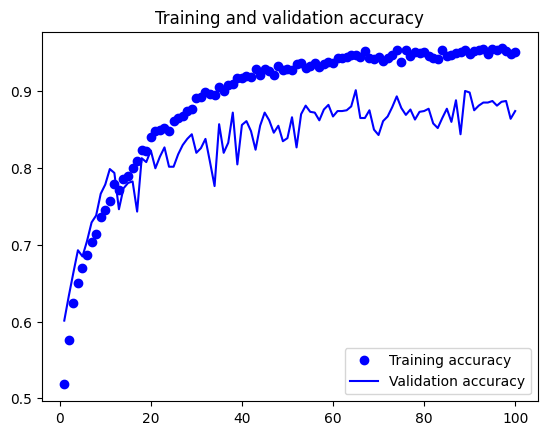

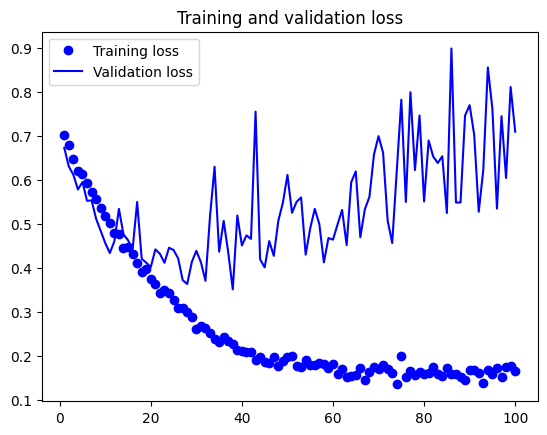

In [75]:
import matplotlib.pyplot as plt

accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(accuracy) + 1)

# Plot accuracy
plt.plot(epochs, accuracy, "bo", label="Training accuracy")
plt.plot(epochs, val_accuracy, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.legend()

# Plot loss
plt.figure()
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.legend()

plt.show()

Dankzij data augmentation en dropout overfitten we nu veel later! De validation accuracy is ook omhooggegaan naar 

**Evaluatie op de test set**

In [77]:
test_model = keras.models.load_model(
    "convnet_from_scratch_with_augmentation.keras"
)

test_loss, test_acc = test_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")

62/62 [==============================] - 5s 77ms/step - loss: 0.3277 - accuracy: 0.8744
Test accuracy: 0.874


# Gebruik van pretrained modellen

## 2. Techniek 1: Feature-extractie met een voorgetraind model  
Bij deze methode maak je gebruik van het convolutionele gedeelte van een bestaand, goed getraind netwerk – bijvoorbeeld VGG16, dat getraind werd op het grote ImageNet-dataplatform. Dit model heeft al geleerd om algemene visuele kenmerken te herkennen, zoals randen, hoeken en texturen. Je gebruikt deze 'voorgeleerde' lagen om betekenisvolle kenmerken (features) te extraheren uit je eigen beelden. Deze worden vervolgens ingevoerd in een nieuwe, eenvoudige classifier (bijvoorbeeld een dense laag) die je wel zelf traint.  
Doordat het netwerk de visuele basisprincipes al begrijpt, hoef je met je beperkte dataset enkel nog te leren hoe je die bestaande kenmerken koppelt aan jouw specifieke classificatietaak (zoals honden versus katten). 

**Feature extractie** betekent dus dat je gebruikmaakt van de representaties die een eerder getraind model heeft geleerd, om interessante kenmerken (features) te halen uit nieuwe gegevens. Deze kenmerken geef je vervolgens door aan een nieuwe classifier (bijvoorbeeld een dense layer) die je vanaf nul traint.

Bij convolutionele netwerken (convnets) bestaat een model meestal uit twee delen:

1. Een **convolutionele basis**: dit zijn lagen met convoluties en pooling die generieke visuele kenmerken leren (zoals randen, vormen, texturen).
2. Een **densely connected classifier**: dit deel leert voorspellen tot welke klasse een afbeelding behoort.

Bij feature extractie gebruik je enkel de convolutionele basis van een bestaand model (zoals VGG16), en daarbovenop train je een eigen classifier met je nieuwe data. Je hergebruikt dus alleen het generieke, visueel interpreteerbare deel van het netwerk.

**Waarom gebruiken we niet ook de oorspronkelijke classifier van het voorgetrainde model?**  
Die classifier is specifiek getraind op de oorspronkelijke klassen (zoals die van ImageNet), en bevat dus enkel informatie over die specifieke klassen. Bovendien gaat in die dense layer de ruimtelijke informatie over waar objecten zich in de afbeelding bevinden verloren—terwijl die informatie in veel taken net belangrijk is. Daarom zijn die lagen meestal niet herbruikbaar.

**Let op:** de mate waarin een convolutionele laag generiek of specifiek is, hangt af van hoe diep ze zich in het netwerk bevindt.  
- De eerste lagen leren eenvoudige, algemene patronen zoals randen en kleuren.
- De latere lagen leren meer complexe concepten zoals “kattenoren” of “hondensnuiten”.

Als je nieuwe dataset sterk verschilt van de oorspronkelijke (bijv. medische beelden in plaats van honden en katten), gebruik je best alleen de eerste lagen. Maar als de domeinen op elkaar lijken (zoals bij honden en katten, die ook in ImageNet voorkomen), kan het hergebruiken van diepere lagen alsnog voordeel bieden. 

### 2.1 Feature-extractie met een pretrained model - demo

**Praktisch voorbeeld:** we gaan de convolutionele basis van het VGG16-model (getraind op ImageNet) gebruikt om features te extraheren uit afbeeldingen van honden en katten. Op basis van die features wordt vervolgens een nieuwe classifier getraind. VGG16 is beschikbaar via `keras.applications`.

In [79]:
# Instantiatie van de convolutionele basis: VGG16
conv_base = keras.applications.vgg16.VGG16(
                    weights="imagenet",
                    include_top=False,
                    input_shape=(180, 180, 3))

- **`weights`** geeft aan welk gewicht-bestand (checkpoint) gebruikt moet worden om het model te initialiseren.  
- **`include_top`** bepaalt of de densely connected classifier bovenaan het netwerk wel of niet moet worden meegenomen. Standaard bevat deze classifier de 1.000 klassen van ImageNet. Omdat we onze eigen classifier willen gebruiken (met slechts twee klassen: kat en hond), hoeven we deze dus niet op te nemen.  
- **`input_shape`** is de vorm van de beeldtensors die we aan het netwerk zullen aanbieden. Dit argument is optioneel: als we het niet meegeven, kan het netwerk afbeeldingen van eender welke grootte verwerken. Hier geven we het wél op, zodat we in het overzicht straks kunnen zien hoe de grootte van de feature maps geleidelijk afneemt naarmate er meer convolutionele en poolinglagen worden toegepast.

In [80]:
conv_base.summary()

Model: "vgg16"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_6 (InputLayer)        [(None, 180, 180, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 180, 180, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 180, 180, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 90, 90, 64)        0         
                                                                 
 block2_conv1 (Conv2D)       (None, 90, 90, 128)       73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 90, 90, 128)       147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 45, 45, 128)       0     

De uiteindelijke feature map heeft de vorm (5, 5, 512). Dit is de feature map waarop we een dense classifier zullen plaatsen. Vanaf dit punt zijn er twee mogelijke manieren om verder te werken:

- Optie 1: Voer de convolutionele basis één keer uit op de volledige dataset, sla de gegenereerde output op als een NumPy-array op schijf, en gebruik deze gegevens vervolgens als input voor een afzonderlijke, densely connected classifier.
Deze aanpak is snel en 'goedkoop' *(wat betreft rekenkracht)*, omdat de convolutionele basis – het 'duurste' deel van het model – slechts één keer per afbeelding hoeft te worden uitgevoerd.
Nadeel: je kunt hierbij geen data-augmentatie toepassen, omdat de inputafbeeldingen niet telkens opnieuw door het model gaan.

- Optie 2: Breid het bestaande model (conv_base) uit door Dense-lagen bovenop toe te voegen, en train het volledige model end-to-end op de inputdata.
Deze aanpak maakt het wél mogelijk om data-augmentatie toe te passen, aangezien elke afbeelding bij elke epoch opnieuw door de convolutionele basis gaat.
Nadeel: deze methode is computationeel veel duurder dan de eerste.

#### 2.1.1 Snelle Feature-extractie ZONDER data-augmentatie
We beginnen met het extraheren van features als NumPy-arrays door de `predict()`-methode van het `conv_base`-model aan te roepen op onze trainings-, validatie- en testdatasets.  
Laten we over onze datasets itereren om de VGG16-features te extraheren.

In [81]:
import numpy as np

def get_features_and_labels(dataset):
    all_features = []
    all_labels = []
    for images, labels in dataset:
        preprocessed_images = keras.applications.vgg16.preprocess_input(images)
        features = conv_base.predict(preprocessed_images)
        all_features.append(features)
        all_labels.append(labels)
    return np.concatenate(all_features), np.concatenate(all_labels)

train_features, train_labels = get_features_and_labels(train_dataset)
val_features, val_labels = get_features_and_labels(validation_dataset)
test_features, test_labels = get_features_and_labels(test_dataset)

1/1 [==============================] - 0s 39ms/step


1/1 [==============================] - 1s 761ms/step


Belangrijk om te weten is dat `predict()` (voor de features) **alleen afbeeldingen verwacht, geen labels**. Onze huidige dataset levert echter batches aan die zowel afbeeldingen als bijbehorende labels bevatten.

Daarnaast verwacht het VGG16-model invoer die is **gepreprocessed met de functie** `keras.applications.vgg16.preprocess_input`, die de pixelwaarden schaalt naar een geschikt bereik.

De geëxtraheerde features hebben momenteel de vorm **(aantal samples, 5, 5, 512)**.

In [82]:
train_features.shape

(3965, 5, 5, 512)

Op dit punt kunnen we onze dense classifier definiëren (merk op dat we dropout gebruiken als regularisatietechniek) en deze trainen op de data en labels die we zojuist hebben opgeslagen.

In [83]:
inputs = keras.Input(shape=(5, 5, 512))

# Zet de 3D-featuremap om naar een 1D vector
x = layers.Flatten()(inputs)

# Dicht verbonden laag met 256 units
x = layers.Dense(256)(x)

# Dropout voor regularisatie
x = layers.Dropout(0.5)(x)

# Uitvoersigmoid voor binaire classificatie
outputs = layers.Dense(1, activation="sigmoid")(x)

# Bouw het model
model = keras.Model(inputs, outputs)

In [84]:
model.compile(
    loss="binary_crossentropy",
    optimizer="rmsprop",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction.keras",
        save_best_only=True,
        monitor="val_loss"
    )
]

history = model.fit(
    train_features, train_labels,
    epochs=20,
    validation_data=(val_features, val_labels),
    callbacks=callbacks
)

Epoch 1/20
124/124 [==============================] - 2s 16ms/step - loss: 12.5264 - accuracy: 0.9422 - val_loss: 4.6921 - val_accuracy: 0.9698
Epoch 2/20
124/124 [==============================] - 2s 15ms/step - loss: 3.1238 - accuracy: 0.9811 - val_loss: 4.2360 - val_accuracy: 0.9718
Epoch 3/20
124/124 [==============================] - 2s 15ms/step - loss: 2.0091 - accuracy: 0.9854 - val_loss: 3.9121 - val_accuracy: 0.9768
Epoch 4/20
124/124 [==============================] - 2s 15ms/step - loss: 1.5083 - accuracy: 0.9912 - val_loss: 5.8514 - val_accuracy: 0.9708
Epoch 5/20
124/124 [==============================] - 2s 15ms/step - loss: 0.8256 - accuracy: 0.9917 - val_loss: 5.6335 - val_accuracy: 0.9708
Epoch 6/20
124/124 [==============================] - 2s 15ms/step - loss: 0.2905 - accuracy: 0.9982 - val_loss: 4.8686 - val_accuracy: 0.9768
Epoch 7/20
124/124 [==============================] - 2s 15ms/step - loss: 0.6557 - accuracy: 0.9950 - val_loss: 6.7898 - val_accuracy: 0.969

Het trainen gaat zeer snel omdat we alleen te maken hebben met twee Dense-lagen — een epoch duurt minder dan één seconde, zelfs op een CPU.  
  
Laten we nu kijken naar de loss- en accuracycurves tijdens de training

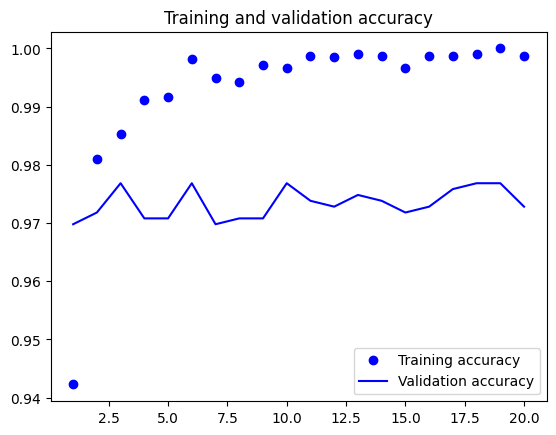

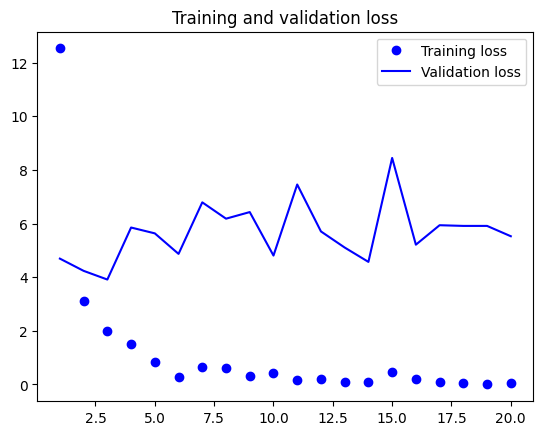

In [85]:
import matplotlib.pyplot as plt

acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(acc) + 1)

# Plot training & validation accuracy
plt.plot(epochs, acc, "bo", label="Training accuracy")
plt.plot(epochs, val_acc, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.legend()

# Nieuwe figuur voor verlies
plt.figure()

# Plot training & validation loss
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.legend()

plt.show()

We behalen een **validatienauwkeurigheid van ongeveer 97%** – veel beter dan bij het kleine model dat we eerder vanaf nul trainden.  

Toch is deze vergelijking **niet helemaal eerlijk**, want het voorgetrainde model is getraind op ImageNet, dat al veel **kat- en hondafbeeldingen** bevat. Daardoor beschikt het model al over kennis die perfect aansluit op deze taak. Dat zal niet altijd zo zijn bij andere taken.

Tegelijkertijd laten de grafieken zien dat het model **al bijna vanaf het begin overfit**, ondanks het gebruik van Dropout met een relatief hoge waarde.  
De oorzaak? In deze aanpak werd **géén data-augmentatie** gebruikt – en dat is **essentieel** om overfitting te voorkomen bij kleine afbeeldingsdatasets.

#### 2.1.2 Feature-extractie mét data-augmentatie
We bekijken nu een alternatieve aanpak van feature-extractie die **trager en zwaarder is**, maar het wél mogelijk maakt om **data-augmentatie toe te passen tijdens training**.

Deze methode bestaat uit:
1. Een nieuw model bouwen waarin de **convolutionele basis (`conv_base`)** wordt gekoppeld aan een nieuwe **dense classifier**.
2. Het volledige model end-to-end trainen op de originele afbeeldingen.

Voor we dit doen, moeten we de convolutionele basis **"bevriezen"** (freezen).  
Dit betekent dat we de gewichten van die lagen **niet laten aanpassen tijdens de training**.

Waarom? Omdat de bovenliggende Dense-layers willekeurig zijn geïnitialiseerd, kunnen ze tijdens training grote updates veroorzaken, die de zorgvuldig aangeleerde representaties van `conv_base` **zouden verpesten**.

In Keras doe je dit door de **`trainable` eigenschap op `False`** te zetten:

In [86]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False
)

conv_base.trainable = False

Het instellen van `trainable` op `False` zorgt ervoor dat de lijst met **trainbare gewichten** van de laag of het model **leeg wordt gemaakt**.

In [87]:
conv_base.trainable = True
print("This is the number of trainable weights before freezing the conv base:", 
      len(conv_base.trainable_weights))

conv_base.trainable = False
print("This is the number of trainable weights after freezing the conv base:", 
      len(conv_base.trainable_weights))

This is the number of trainable weights before freezing the conv base: 26
This is the number of trainable weights after freezing the conv base: 0


Nu kunnen we een nieuw model creëren dat de volgende onderdelen aan elkaar koppelt:

1. Een **data-augmentatiestap**  
2. Onze **frozen convolutional basis**  
3. Een **Dense classifier**

In [88]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
])

inputs = keras.Input(shape=(180, 180, 3))
x = data_augmentation(inputs)  # Pas data-augmentatie toe
x = keras.applications.vgg16.preprocess_input(x)  # Schaal inputwaarden
x = conv_base(x)  # Bevroren convolutionele basis (VGG16)
x = layers.Flatten()(x)
x = layers.Dense(256)(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)

model.compile(
    loss="binary_crossentropy",
    optimizer="rmsprop",
    metrics=["accuracy"]
)

Met deze opstelling worden alleen de gewichten van de twee **Dense-lagen** die we hebben toegevoegd getraind. Dat zijn in totaal **vier gewichtstensors**: twee per laag (de hoofdgewichtmatrix en de biasvector).  

Let op: om deze wijzigingen effect te laten hebben, moet je het model eerst **compileren**. Als je na het compileren nog iets wijzigt aan de trainbaarheid van gewichten, moet je het model opnieuw compileren – anders worden die wijzigingen genegeerd.

Laten we nu het model trainen. Dankzij **data-augmentatie** zal het veel langer duren voor het model begint te overfitten, dus we kunnen gerust langer trainen – **laten we 50 epochs doen**.

---

> **OPMERKING**  
> Deze techniek is behoorlijk zwaar qua rekenkracht. Je moet dit **alleen proberen als je toegang hebt tot een GPU** (zoals de gratis GPU in Google Colab).  
> Op een CPU is dit praktisch **niet werkbaar**.  
> Kun je geen GPU gebruiken? Dan is de vorige (snellere) techniek een betere keuze.

In [89]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction_with_data_augmentation.keras",
        save_best_only=True,
        monitor="val_loss"
    )
]

In [90]:
history = model.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=callbacks
)

Epoch 1/50
124/124 [==============================] - 131s 1s/step - loss: 15.8940 - accuracy: 0.9117 - val_loss: 5.9613 - val_accuracy: 0.9658
Epoch 2/50
124/124 [==============================] - 130s 1s/step - loss: 5.6524 - accuracy: 0.9544 - val_loss: 2.8379 - val_accuracy: 0.9748
Epoch 3/50
124/124 [==============================] - 132s 1s/step - loss: 4.7114 - accuracy: 0.9619 - val_loss: 3.3539 - val_accuracy: 0.9778
Epoch 4/50
124/124 [==============================] - 134s 1s/step - loss: 3.7879 - accuracy: 0.9682 - val_loss: 2.4290 - val_accuracy: 0.9799
Epoch 5/50
124/124 [==============================] - 138s 1s/step - loss: 2.5085 - accuracy: 0.9735 - val_loss: 1.8613 - val_accuracy: 0.9809
Epoch 6/50
124/124 [==============================] - 137s 1s/step - loss: 2.2110 - accuracy: 0.9702 - val_loss: 3.2443 - val_accuracy: 0.9718
Epoch 7/50
124/124 [==============================] - 138s 1s/step - loss: 2.0669 - accuracy: 0.9730 - val_loss: 2.2212 - val_accuracy: 0.980

124/124 [==============================] - 140s 1s/step - loss: 0.3837 - accuracy: 0.9887 - val_loss: 2.1116 - val_accuracy: 0.9748
Epoch 42/50
124/124 [==============================] - 152s 1s/step - loss: 0.4042 - accuracy: 0.9897 - val_loss: 2.1853 - val_accuracy: 0.9799
Epoch 43/50
124/124 [==============================] - 135s 1s/step - loss: 0.4037 - accuracy: 0.9892 - val_loss: 2.1971 - val_accuracy: 0.9748
Epoch 44/50
124/124 [==============================] - 137s 1s/step - loss: 0.4937 - accuracy: 0.9887 - val_loss: 2.4159 - val_accuracy: 0.9728
Epoch 45/50
124/124 [==============================] - 139s 1s/step - loss: 0.2575 - accuracy: 0.9929 - val_loss: 2.4337 - val_accuracy: 0.9748
Epoch 46/50
124/124 [==============================] - 139s 1s/step - loss: 0.2754 - accuracy: 0.9922 - val_loss: 3.6354 - val_accuracy: 0.9708
Epoch 47/50
124/124 [==============================] - 137s 1s/step - loss: 0.3049 - accuracy: 0.9924 - val_loss: 2.5646 - val_accuracy: 0.9768
Epoc

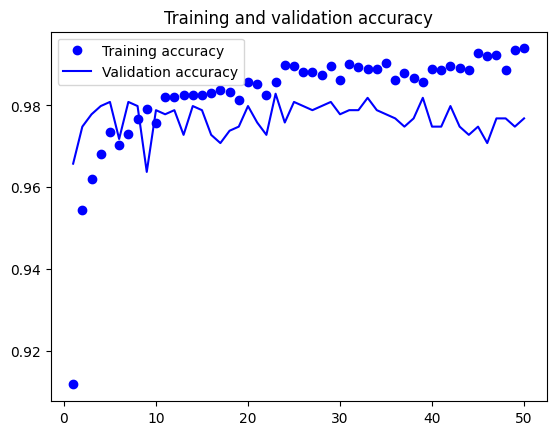

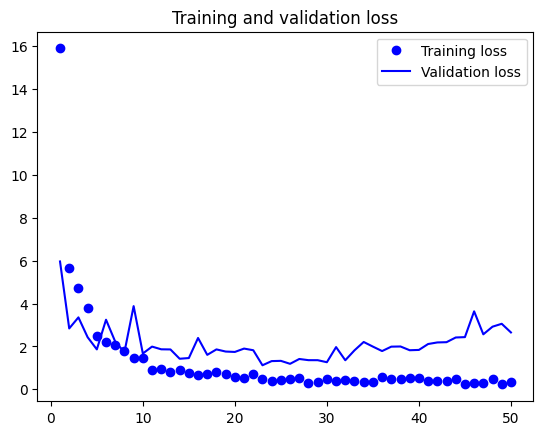

In [91]:
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(accuracy) + 1)

# Plot accuracy
plt.plot(epochs, accuracy, "bo", label="Training accuracy")
plt.plot(epochs, val_accuracy, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.legend()

# Plot loss
plt.figure()
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.legend()

plt.show()

In [92]:
# We testen de test accuracy:
test_model = keras.models.load_model(
    "feature_extraction_with_data_augmentation.keras"
)

test_loss, test_acc = test_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")

62/62 [==============================] - 53s 855ms/step - loss: 1.7489 - accuracy: 0.9758
Test accuracy: 0.976


We behalen een testnauwkeurigheid van 97,5%. Dat is slechts een **bescheiden verbetering** ten opzichte van de vorige testnauwkeurigheid, wat een beetje teleurstellend is gezien de sterke resultaten op de validatieset.

De nauwkeurigheid van een model hangt altijd af van de **set voorbeelden waarop je het evalueert**! Sommige datasets kunnen nu eenmaal moeilijker zijn dan andere, en **goede prestaties op één set betekenen niet automatisch dat het model even goed zal presteren op andere sets**.

## 2. Techniek 2: Fine-tuning van een voorgetraind model

Fine-tuning gaat een stapje verder dan feature-extractie. In plaats van het voorgetrainde convolutionele deel volledig 'vast te zetten' (freezen), maak je enkele van de bovenste lagen weer trainbaar. Die lagen worden vervolgens samen met je nieuwe classifier hertraind, maar met een zeer lage leersnelheid (*learning rate*). 

Hierdoor kan het model de eerder geleerde kenmerken aanpassen aan jouw specifieke data.  
De motivatie hierachter is dat de eerste lagen van een CNN meestal algemene patronen leren (zoals randen en vormen), terwijl de latere lagen eerder taakspecifiek zijn (zoals de vorm van een hondensnuit of kattenoor). Door die laatste lagen bij te stellen, kan het model zich beter aanpassen aan jouw specifieke classificatietaak. 

Fine-tuning houdt dus in dat je enkele van de bovenste lagen van een 'bevroren' modelbasis (die werd gebruikt voor feature-extractie) **weer trainbaar maakt**, en vervolgens **samen met het nieuw toegevoegde deel** van het model (in dit geval de dense classifier) traint.

Dit heet *fine-tuning* omdat het de meer abstracte representaties van het bestaande model **lichtjes bijstuurt**, zodat ze beter aansluiten op het specifieke probleem.

Eerder werd vermeld dat het nodig is om de convolutionele basis van VGG16 te **bevriezen** voordat je een willekeurig geïnitialiseerde classifier erbovenop kunt trainen.  

Om dezelfde reden is het ook **alleen mogelijk om fine-tuning toe te passen op de bovenste lagen van het model nádat de classifier getraind is**.

Als de classifier nog niet getraind is, zal het foutsignaal tijdens training te groot zijn. Hierdoor worden de eerder geleerde representaties van de lagen die je probeert te fine-tunen overschreven of vernietigd.

### De stappen voor fine-tuning van een netwerk zijn als volgt:

1. Voeg ons eigen netwerk toe aan een pretrained basismodel.
2. **Bevries** het basismodel.
3. Train alleen het nieuwe, toegevoegde deel.
4. Maak een aantal lagen in het basismodel opnieuw **trainbaar**.     
5. **Train het volledige netwerk verder**, dus zowel het nieuw toegevoegde deel als de nu vrijgegeven lagen van het basismodel.

De eerste drie stappen hebben we al uitgevoerd tijdens de **feature-extractie**.  

Laten we nu doorgaan met stap 4: we gaan **onze `conv_base` "unfreezen"** (dus opnieuw trainbaar maken), en vervolgens **individuele lagen daarbinnen bevriezen**.

We gaan de laatste drie convolutionele lagen **fine-tunen**, wat betekent dat **alle lagen tot en met `block4_pool` bevroren moeten blijven**, en dat de lagen **`block5_conv1`, `block5_conv2` en `block5_conv3` wel trainbaar** moeten zijn.  

Waarom zouden we niet méér lagen fine-tunen? Waarom niet de hele convolutionele basis?  
Dat **kan wel**, maar je moet met het volgende rekening houden:

- **Lagere lagen** in de convolutionele basis leren **meer algemene, herbruikbare kenmerken**, terwijl de **hogere lagen** meer **gespecialiseerde kenmerken** bevatten.  
  Het is **nuttiger om de gespecialiseerde lagen te fine-tunen**, omdat juist die aangepast moeten worden aan je nieuwe taak.  
  Fine-tunen van eerdere lagen levert **steeds minder op**.

- Hoe **meer parameters je traint**, hoe groter het risico op **overfitting**.  
  De convolutionele basis bevat **15 miljoen parameters**, dus het zou riskant zijn om die volledig te trainen op een kleine dataset.

Daarom is het in deze situatie een **goede strategie om enkel de bovenste twee of drie lagen van de convolutionele basis te fine-tunen**.

Laten we dit nu instellen, beginnend waar we in het vorige voorbeeld gebleven waren.

In [93]:
conv_base.trainable = True

for layer in conv_base.layers[:-4]:
    layer.trainable = False

Nu kunnen we beginnen met het **fine-tunen van het model**.  
We doen dit met de **RMSprop-optimizer**, maar met een **zeer lage leersnelheid (learning rate)**.

De reden voor het gebruik van een lage learning rate is dat we de **wijzigingen aan de representaties in de drie lagen die we fine-tunen zo klein mogelijk willen houden**.  
Als de updates te groot zijn, kunnen ze deze representaties namelijk **beschadigen**.

In [94]:
model.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.RMSprop(learning_rate=1e-5),
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="fine_tuning.keras",
        save_best_only=True,
        monitor="val_loss"
    )
]

history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks
)

Epoch 1/30
124/124 [==============================] - 167s 1s/step - loss: 0.4883 - accuracy: 0.9894 - val_loss: 2.2920 - val_accuracy: 0.9758
Epoch 2/30
124/124 [==============================] - 164s 1s/step - loss: 0.3978 - accuracy: 0.9904 - val_loss: 2.9166 - val_accuracy: 0.9768
Epoch 3/30
124/124 [==============================] - 163s 1s/step - loss: 0.3032 - accuracy: 0.9914 - val_loss: 2.5392 - val_accuracy: 0.9718
Epoch 4/30
124/124 [==============================] - 162s 1s/step - loss: 0.3056 - accuracy: 0.9927 - val_loss: 2.4008 - val_accuracy: 0.9748
Epoch 5/30
124/124 [==============================] - 166s 1s/step - loss: 0.2402 - accuracy: 0.9932 - val_loss: 2.7308 - val_accuracy: 0.9748
Epoch 6/30
124/124 [==============================] - 163s 1s/step - loss: 0.2717 - accuracy: 0.9934 - val_loss: 3.6231 - val_accuracy: 0.9728
Epoch 7/30
124/124 [==============================] - 165s 1s/step - loss: 0.2329 - accuracy: 0.9929 - val_loss: 2.3128 - val_accuracy: 0.9728

We kunnen nu dit model evalueren op de test data:

In [95]:
model = keras.models.load_model("fine_tuning.keras")
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.3f}")

62/62 [==============================] - 55s 884ms/step - loss: 2.1993 - accuracy: 0.9773
Test accuracy: 0.977


We behalen hier een **testnauwkeurigheid van 98,5%** (je eigen resultaat kan ongeveer 1 procentpunt verschillen).  
In de oorspronkelijke **Kaggle-wedstrijd** rond deze dataset zou dit bij de **topresultaten** hebben gehoord.

Toch is dit geen volledig eerlijke vergelijking, aangezien wij gebruik hebben gemaakt van **voorgetrainde features** die al voorkennis bevatten over katten en honden — iets wat de deelnemers destijds **niet mochten gebruiken**.

Het positieve nieuws: dankzij moderne deep learning-technieken zijn we erin geslaagd om dit resultaat te behalen met **slechts een fractie van de trainingsdata** die beschikbaar was voor de competitie (ongeveer 10%).

Er is namelijk een **groot verschil tussen trainen op 20.000 afbeeldingen versus op slechts 4.000**.

Je beschikt nu over een **krachtige set tools** om beeldclassificatieproblemen aan te pakken — vooral wanneer je werkt met **kleine datasets**!

### Samenvatting

- **Convolutionele netwerken (convnets)** zijn de beste keuze voor computer vision-taken.  
  Je kunt er zelfs bij kleine datasets **redelijke resultaten mee behalen** door vanaf nul te trainen.

- Convnets werken door **hiërarchieën van patronen en visuele concepten** te leren.

- Bij kleine datasets is **overfitting** meestal het grootste probleem.  
  **Data-augmentatie** is een krachtige techniek om dit tegen te gaan.

- Het is eenvoudig om een bestaand convnet te hergebruiken op een nieuwe dataset via **feature-extractie** — dit is erg waardevol bij kleine datasets.

- Naast feature-extractie kun je ook **fine-tuning** toepassen.  
  Hiermee pas je bestaande representaties aan een nieuw probleem aan, waardoor je prestaties **nog verder kunt verbeteren**.